# Artifact-only analysis of the 45-run experiment matrix

This notebook reads saved scores and metadata only. It does **not** fit models, read checkpoints, import Torch,
or require a GPU. The complete inventory is 25 classical runs, 10 selective (`top2`) runs, and 10 full
fine-tuning runs, always over seeds 0--4: 45 runs, nine models, and three families.

The design focuses on structured-versus-text classical LR, full-versus-top2 adaptation within
text/fused arms, and fused-versus-text comparisons within top2/full arms.

The full and top2 arms use custom two-logit DistilBERT classifiers, first-token/CLS pooling, at most 512 tokens,
unweighted cross-entropy, effective batch size 16, learning rate 2e-5, and at most four epochs. Validation AP
selects the checkpoint and validation F1 selects the reporting threshold. Top2 freezes embeddings and encoder
layers 0--3 while tuning layers 4--5 and the head; full tuning updates the encoder and head. A fused arm
concatenates training-fold structured features to the head input. One optimization seed is used per data split,
so split and optimization variability are confounded.

**AP always means average precision**, not an unspecified or interpolated PR-AUC. All reported test comparisons
are exploratory, not a basis for selecting a final winner.

In [1]:
import json
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
elif (Path.cwd() / "code" / "modules").is_dir():
    os.chdir("code")
assert Path("modules").is_dir(), "run with notebook resources path code/notebooks or from the repository"
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve

from modules import data_helper as dh
from modules import eval_helper as ev
from modules import report as rp
from modules import results_helper as rh

SEEDS = tuple(range(5))
DIRS = {
    "classical": Path("outputs/classical"),
    "distilbert_top2": Path("outputs/distilbert_top2"),
    "finetuned": Path("outputs/finetuned"),
}
EXPECTED_MODELS = {
    "classical": ("dummy_majority", "logreg_text", "logreg", "tree", "ocsvm"),
    "distilbert_top2": ("distilbert_top2_text", "distilbert_top2_fused"),
    "finetuned": ("distilbert_text", "distilbert_fused"),
}
STORED_GROUPS = {
    "classical": "classical",
    "distilbert_top2": "finetuned_top2",
    "finetuned": "finetuned",
}
MODEL_ARM = {model: arm for arm, models in EXPECTED_MODELS.items() for model in models}
MODEL_ORDER = tuple(MODEL_ARM)
MODEL_LABELS = {
    "dummy_majority": "majority dummy",
    "logreg_text": "text-only LR",
    "logreg": "structured LR",
    "tree": "decision tree",
    "ocsvm": "one-class SVM",
    "distilbert_top2_text": "top2 text",
    "distilbert_top2_fused": "top2 fused",
    "distilbert_text": "full text",
    "distilbert_fused": "full fused",
}
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
rp.use_style()

## 1. Verified result matrix

`rh.verify_results` requires exactly the expected model/seed files,
checks every run's data fingerprint, exact split rows and labels, recomputes every saved validation/test
metric from the raw scores, and checks that each threshold is the validation-F1 threshold (the majority
dummy keeps its fixed 0.5). For the fine-tuned runs, the saved checkpoint must also be the epoch with the
highest validation AP.

In [2]:
df = dh.load_processed()
split_cache = {seed: dh.load_splits(f"splits/seed{seed}.npz", df) for seed in SEEDS}
res = rh.verify_results(
    {DIRS[arm]: models for arm, models in EXPECTED_MODELS.items()},
    df["fraudulent"].to_numpy(), split_cache, dh.data_fingerprint(df),
)
res["arm"] = res["model"].map(MODEL_ARM)
assert len(res) == 45 and (res["group"] == res["arm"].map(STORED_GROUPS)).all()

for arm in ("distilbert_top2", "finetuned"):
    for model in EXPECTED_MODELS[arm]:
        for seed in SEEDS:
            with open(DIRS[arm] / f"{model}_seed{seed}.json", encoding="utf-8") as source:
                record = json.load(source)
            history = record["history"]
            best = max(history, key=lambda row: row["val_pr_auc"])
            assert best["epoch"] == record["best_params"]["best_epoch"], (model, seed)
            assert best["val_pr_auc"] == record["val"]["pr_auc"], (model, seed)

display(res.groupby("arm")["model"].agg(models="nunique", runs="size"))
print(f"PASS: {len(res)} runs verified; every fine-tuned run kept its best validation-AP epoch.")
print(f"Data: {len(df):,} rows, {int(df['fraudulent'].sum()):,} fraud rows, "
      f"{df['group'].nunique():,} related-ad groups.")

,models,runs
arm,,
classical,5,25
distilbert_top2,2,10
finetuned,2,10


PASS: 45 runs verified; every fine-tuned run kept its best validation-AP epoch.
Data: 17,597 rows, 856 fraud rows, 4,482 related-ad groups.


## 2. Performance, generalization, and recorded time

Entries are **mean ± sample standard deviation over the five split/optimization-seed pairs**. They are descriptive,
not confidence intervals or five independent optimizer replications. F1, precision, and recall use each run's own
validation-selected (or majority-dummy) threshold. Train AP was computed on fitted training rows, so train-minus-
validation/test gaps are descriptive optimism measures rather than unbiased learning-curve estimates.

In [3]:
def mean_std(values: pd.Series | np.ndarray, decimals: int = 4) -> str:
    """Format a sample mean and sample standard deviation without hiding uncertainty."""
    array = np.asarray(values, dtype=float)
    assert array.size == 5 and np.isfinite(array).all()
    return f"{array.mean():.{decimals}f} ± {array.std(ddof=1):.{decimals}f}"


def aggregate_by_model(
    metrics: dict[str, str], decimals: int = 4, frame: pd.DataFrame | None = None
) -> pd.DataFrame:
    """Aggregate metrics by model in the fixed, design-based display order."""
    frame = res if frame is None else frame
    rows = []
    for model in MODEL_ORDER:
        model_runs = frame[frame["model"] == model]
        row = {"arm": MODEL_ARM[model], "model": model}
        for source, label in metrics.items():
            row[label] = mean_std(model_runs[source], decimals)
        rows.append(row)
    return pd.DataFrame(rows).set_index(["arm", "model"])


performance_summary = aggregate_by_model({
    "val_pr_auc": "validation AP",
    "test_pr_auc": "test AP",
    "test_f1": "test F1",
    "test_precision": "test precision",
    "test_recall": "test recall",
})
print("Per-model mean ± sample SD (five runs each):")
display(performance_summary)

gap_runs = res.copy()
gap_runs["train_val_ap_gap"] = gap_runs["train_pr_auc"] - gap_runs["val_pr_auc"]
gap_runs["train_test_ap_gap"] = gap_runs["train_pr_auc"] - gap_runs["test_pr_auc"]
gap_runs["test_val_ap_change"] = gap_runs["test_pr_auc"] - gap_runs["val_pr_auc"]
generalization_summary = aggregate_by_model({
    "train_pr_auc": "train AP",
    "train_val_ap_gap": "train−validation AP gap",
    "train_test_ap_gap": "train−test AP gap",
    "test_val_ap_change": "test−validation AP change",
}, frame=gap_runs)
timing = res.groupby("model")["seconds"].agg(["mean", "std"]).reindex(MODEL_ORDER)
index_values = generalization_summary.index
timing = timing.set_index(index_values)
generalization_summary["recorded seconds, mean"] = timing["mean"].round(2)
generalization_summary["recorded seconds, SD"] = timing["std"].round(2)
print("Generalization gaps and saved wall-clock run times:")
display(generalization_summary)

Per-model mean ± sample SD (five runs each):


validation AP          test AP          test F1   test precision      test recall
arm             model                                                                                                     
classical       dummy_majority         0.0456 ± 0.0029  0.0478 ± 0.0048  0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000
                logreg_text            0.6736 ± 0.1038  0.6568 ± 0.1241  0.6005 ± 0.1368  0.7628 ± 0.1077  0.5044 ± 0.1571
                logreg                 0.6756 ± 0.1212  0.6753 ± 0.1383  0.6188 ± 0.1537  0.8627 ± 0.0527  0.5045 ± 0.1851
                tree                   0.3739 ± 0.1439  0.4164 ± 0.1345  0.4666 ± 0.1324  0.6077 ± 0.1746  0.4000 ± 0.1441
                ocsvm                  0.0449 ± 0.0061  0.0488 ± 0.0052  0.0818 ± 0.0193  0.0441 ± 0.0102  0.7129 ± 0.3779
distilbert_top2 distilbert_top2_text   0.5444 ± 0.1805  0.5094 ± 0.1664  0.4258 ± 0.1499  0.5747 ± 0.2830  0.3976 ± 0.1410
                distilbert_top2_fused  0.5638 ± 0.1817  0.5597 ± 0.1420  0.4907 ± 0.1531  0.6650 ± 0.2833  0.4266 ± 0.1271
finetuned       distilbert_text        0.6786 ± 0.1124  0.6153 ± 0.1091  0.5159 ± 0.1575  0.6939 ± 0.2798  0.4840 ± 0.1475
                distilbert_fused       0.6570 ± 0.1243  0.5971 ± 0.1592  0.5824 ± 0.1409  0.7669 ± 0.1889  0.4734 ± 0.1257

Generalization gaps and saved wall-clock run times:


train AP train−validation AP gap train−test AP gap test−validation AP change  recorded seconds, mean  recorded seconds, SD
arm             model                                                                                                                                                   
classical       dummy_majority         0.0499 ± 0.0014         0.0043 ± 0.0033   0.0021 ± 0.0059           0.0022 ± 0.0069                    0.00                  0.00
                logreg_text            1.0000 ± 0.0000         0.3264 ± 0.1038   0.3432 ± 0.1242          -0.0168 ± 0.2182                   44.78                  5.40
                logreg                 1.0000 ± 0.0000         0.3244 ± 0.1212   0.3247 ± 0.1383          -0.0002 ± 0.2511                   52.00                  8.65
                tree                   0.8973 ± 0.0608         0.5234 ± 0.1696   0.4809 ± 0.1390           0.0425 ± 0.2717                   60.02                  2.69
                ocsvm                  0.9412 ± 0.0191         0.8963 ± 0.0182   0.8924 ± 0.0150           0.0039 ± 0.0089                  194.54                 10.11
distilbert_top2 distilbert_top2_text   0.9504 ± 0.0258         0.4060 ± 0.1856   0.4410 ± 0.1638          -0.0350 ± 0.2968                  128.07                  4.49
                distilbert_top2_fused  0.9335 ± 0.0655         0.3698 ± 0.1368   0.3738 ± 0.1515          -0.0040 ± 0.2430                  117.97                  7.80
finetuned       distilbert_text        0.9900 ± 0.0070         0.3115 ± 0.1103   0.3747 ± 0.1059          -0.0632 ± 0.1735                  162.12                  5.27
                distilbert_fused       0.9715 ± 0.0362         0.3146 ± 0.1271   0.3745 ± 0.1330          -0.0599 ± 0.2232                  154.40                 15.74

## 3. Seed-paired ablations

Every delta is **left model minus right model on the same seed**, so positive values favor the left model. Pairing
aligns the data split; it does not remove the confounding of split seed with optimization seed. Per-seed tables show
validation/test AP and validation/test F1 changes; summaries add sample SD and positive counts.

In [4]:
PAIR_METRICS = {
    "val_pr_auc": "validation AP Δ",
    "test_pr_auc": "test AP Δ",
    "val_f1": "validation F1 Δ",
    "test_f1": "test F1 Δ",
}


def paired_deltas(left_model: str, right_model: str, label: str) -> pd.DataFrame:
    """Compute left-minus-right metrics after asserting complete same-seed pairs."""
    left = res[res["model"] == left_model].set_index("seed").sort_index()
    right = res[res["model"] == right_model].set_index("seed").sort_index()
    assert left.index.tolist() == right.index.tolist() == list(SEEDS)
    output = pd.DataFrame({column: left[source].to_numpy() - right[source].to_numpy()
                           for source, column in PAIR_METRICS.items()}, index=left.index)
    output.index.name = "seed"
    output.insert(0, "comparison", label)
    return output.set_index("comparison", append=True).reorder_levels(["comparison", "seed"])


def paired_summary(deltas: pd.DataFrame) -> pd.DataFrame:
    """Summarize paired deltas with mean, sample SD, and strictly positive counts."""
    rows = []
    for comparison, rows_for_comparison in deltas.groupby(level="comparison", sort=False):
        assert len(rows_for_comparison) == 5
        row = {"comparison": comparison}
        for column in PAIR_METRICS.values():
            row[column + " (mean ± SD)"] = mean_std(rows_for_comparison[column])
        row["test AP positive"] = f"{int((rows_for_comparison['test AP Δ'] > 0).sum())}/5"
        row["test F1 positive"] = f"{int((rows_for_comparison['test F1 Δ'] > 0).sum())}/5"
        rows.append(row)
    return pd.DataFrame(rows).set_index("comparison")


classical_delta = paired_deltas(
    "logreg", "logreg_text", "structured classical LR − text-only classical LR"
)
print("(a) Structured classical LR minus text-only LR:")
display(classical_delta.droplevel("comparison").round(4))
display(paired_summary(classical_delta))

(a) Structured classical LR minus text-only LR:


,validation AP Δ,test AP Δ,validation F1 Δ,test F1 Δ
seed,,,,
0,-0.0309,0.0901,-0.0525,0.0857
1,0.0481,0.0602,0.0286,0.0667
2,0.0061,0.0071,-0.0164,-0.0077
3,-0.0376,-0.0168,0.0099,-0.0237
4,0.0242,-0.0480,0.0302,-0.0298


,validation AP Δ (mean ± SD),test AP Δ (mean ± SD),validation F1 Δ (mean ± SD),test F1 Δ (mean ± SD),test AP positive,test F1 positive
comparison,,,,,,
structured classical LR − text-only classical LR,0.0020 ± 0.0363,0.0185 ± 0.0563,-0.0000 ± 0.0349,0.0183 ± 0.0539,3/5,2/5


### (b) Adaptation ablation: full minus top2

Text-only and late-fusion arms are compared separately. This contrasts full-encoder tuning with tuning only the
top two encoder layers and head, while holding the representation family and fusion arm fixed within each pair.

In [5]:
adaptation_deltas = pd.concat([
    paired_deltas("distilbert_text", "distilbert_top2_text", "full text − top2 text"),
    paired_deltas("distilbert_fused", "distilbert_top2_fused", "full fused − top2 fused"),
])
display(adaptation_deltas.round(4))
display(paired_summary(adaptation_deltas))

validation AP Δ  test AP Δ  validation F1 Δ  test F1 Δ
comparison              seed                                                        
full text − top2 text   0              0.3923     0.1324           0.4439     0.1343
                        1             -0.0449     0.0262          -0.0403    -0.2140
                        2              0.0355     0.1590           0.0035     0.1611
                        3              0.1668     0.0001           0.0907    -0.0353
                        4              0.1210     0.2119           0.1313     0.4046
full fused − top2 fused 0              0.3395     0.0426           0.3057     0.0141
                        1             -0.0419     0.1035          -0.0436     0.1634
                        2             -0.0209     0.0126           0.0045     0.0730
                        3              0.0906     0.0706           0.0246     0.0157
                        4              0.0986    -0.0427           0.1463     0.1923

,validation AP Δ (mean ± SD),test AP Δ (mean ± SD),validation F1 Δ (mean ± SD),test F1 Δ (mean ± SD),test AP positive,test F1 positive
comparison,,,,,,
full text − top2 text,0.1341 ± 0.1656,0.1059 ± 0.0899,0.1258 ± 0.1904,0.0901 ± 0.2313,5/5,3/5
full fused − top2 fused,0.0932 ± 0.1516,0.0373 ± 0.0560,0.0875 ± 0.1406,0.0917 ± 0.0828,4/5,5/5


### (c) Fusion ablation: fused minus text-only

The comparison is made within top2 and within full tuning. Validation AP is threshold-free; test F1 additionally
depends on transfer of the separately selected validation-F1 threshold.

In [6]:
fusion_deltas = pd.concat([
    paired_deltas(
        "distilbert_top2_fused", "distilbert_top2_text", "top2 fused − top2 text"
    ),
    paired_deltas("distilbert_fused", "distilbert_text", "full fused − full text"),
])
display(fusion_deltas.round(4))
display(paired_summary(fusion_deltas))

validation AP Δ  test AP Δ  validation F1 Δ  test F1 Δ
comparison             seed                                                        
top2 fused − top2 text 0              0.0190     0.0364           0.1003     0.1682
                       1              0.0157    -0.0518          -0.0010     0.0182
                       2             -0.0175     0.0647          -0.0436     0.0129
                       3              0.0272     0.0047           0.0182     0.0301
                       4              0.0523     0.1977           0.0182     0.0952
full fused − full text 0             -0.0337    -0.0533          -0.0379     0.0480
                       1              0.0187     0.0255          -0.0043     0.3956
                       2             -0.0740    -0.0818          -0.0426    -0.0752
                       3             -0.0489     0.0752          -0.0479     0.0812
                       4              0.0299    -0.0569           0.0332    -0.1171

,validation AP Δ (mean ± SD),test AP Δ (mean ± SD),validation F1 Δ (mean ± SD),test F1 Δ (mean ± SD),test AP positive,test F1 positive
comparison,,,,,,
top2 fused − top2 text,0.0193 ± 0.0251,0.0503 ± 0.0931,0.0184 ± 0.0523,0.0649 ± 0.0665,4/5,5/5
full fused − full text,-0.0216 ± 0.0445,-0.0183 ± 0.0660,-0.0199 ± 0.0342,0.0665 ± 0.2016,2/5,3/5


### Validation-to-test sign reversals

A reversal means a paired delta changes sign between validation and test. AP reversals are threshold-free evidence
of split dependence; F1 reversals also include threshold transfer. These counts justify caution about threshold-
overfit and split generalization, but **do not by themselves prove either overfitting or a causal explanation**.

In [7]:
all_key_deltas = pd.concat([
    classical_delta, adaptation_deltas, fusion_deltas
])
reversal_rows = []
for comparison, rows in all_key_deltas.groupby(level="comparison", sort=False):
    reversal_rows.append({
        "comparison": comparison,
        "AP validation/test sign reversals": int(
            ((rows["validation AP Δ"] * rows["test AP Δ"]) < 0).sum()
        ),
        "F1 validation/test sign reversals": int(
            ((rows["validation F1 Δ"] * rows["test F1 Δ"]) < 0).sum()
        ),
    })
reversal_summary = pd.DataFrame(reversal_rows).set_index("comparison")
print("Counts out of five paired splits:")
display(reversal_summary)

Counts out of five paired splits:


,AP validation/test sign reversals,F1 validation/test sign reversals
comparison,,
structured classical LR − text-only classical LR,2,3
full text − top2 text,1,1
full fused − top2 fused,3,1
top2 fused − top2 text,2,2
full fused − full text,2,4


## 4. Split concentration and variability diagnostics

Related-ad groups never cross a split, but they are not equally sized. The table measures both overall group size
and fraud-label concentration. Large concentration motivates qualitative caution about split variability; it does
not identify why any model changed rank.

In [8]:
split_rows = []
for seed, splits in split_cache.items():
    validation = df.iloc[splits["val"]]
    test = df.iloc[splits["test"]]
    group_stats = test.groupby("group")["fraudulent"].agg(["size", "sum"])
    test_positives = int(test["fraudulent"].sum())
    split_rows.append({
        "seed": seed,
        "validation rows": len(validation),
        "validation fraud": int(validation["fraudulent"].sum()),
        "test rows": len(test),
        "test fraud": test_positives,
        "largest test group rows": int(group_stats["size"].max()),
        "largest test group %": 100 * group_stats["size"].max() / len(test),
        "largest fraud-group count": int(group_stats["sum"].max()),
        "largest fraud-group % of test fraud": 100 * group_stats["sum"].max() / test_positives,
        "top-5 fraud groups % of test fraud": 100 * group_stats["sum"].nlargest(5).sum() / test_positives,
    })
split_diagnostics = pd.DataFrame(split_rows).set_index("seed")
display(split_diagnostics.round(2))
transformer_models = EXPECTED_MODELS["distilbert_top2"] + EXPECTED_MODELS["finetuned"]
minimum_ap_seeds = {
    model: int(res[res["model"] == model].set_index("seed")["test_pr_auc"].idxmin())
    for model in transformer_models
}
print("Seed with minimum test AP for each fine-tuned model:", minimum_ap_seeds)
print("Seed with the most concentrated test fraud:",
      int(split_diagnostics["largest fraud-group % of test fraud"].idxmax()))

,validation rows,validation fraud,test rows,test fraud,largest test group rows,largest test group %,largest fraud-group count,largest fraud-group % of test fraud,top-5 fraud groups % of test fraud
seed,,,,,,,,,
0,3447,151,3345,170,723,21.61,49,28.82,54.71
1,3564,175,3719,181,723,19.44,42,23.20,39.78
2,3758,182,3438,137,178,5.18,20,14.60,36.50
3,3784,162,3199,152,183,5.72,49,32.24,44.08
4,3190,140,3589,187,723,20.14,20,10.70,41.71


Seed with minimum test AP for each fine-tuned model: {'distilbert_top2_text': 2, 'distilbert_top2_fused': 2, 'distilbert_text': 2, 'distilbert_fused': 2}
Seed with the most concentrated test fraud: 3


## 5. Measured findings

Headline test AP and the paired win counts, computed from the loaded artifacts.

In [9]:
def model_mean(model: str, metric: str = "test_pr_auc") -> float:
    """Return one model's five-run mean for a saved metric."""
    return float(res.loc[res["model"] == model, metric].mean())


test_ap = res.pivot(index="seed", columns="model", values="test_pr_auc")

headline = res[res["model"].isin([
    "logreg", *EXPECTED_MODELS["distilbert_top2"], *EXPECTED_MODELS["finetuned"]
])].groupby("model")["test_pr_auc"].agg(["mean", "std"])
headline = headline.reindex([
    "logreg", *EXPECTED_MODELS["distilbert_top2"], *EXPECTED_MODELS["finetuned"]
])
print("Headline test AP, mean and sample SD:")
display(headline.round(6))
for full_model in ("distilbert_text", "distilbert_fused"):
    wins = int((test_ap["logreg"] > test_ap[full_model]).sum())
    print(f"Structured LR has higher test AP than {MODEL_LABELS[full_model]} in {wins}/5 splits.")
print(f"Structured LR mean test AP: {model_mean('logreg'):.4f} "
      f"({model_mean('logreg'):.3f} to three decimals).")
for comparison, rows in adaptation_deltas.groupby(level="comparison", sort=False):
    deltas = rows["test AP Δ"]
    print(f"{comparison}: mean test AP Δ {deltas.mean():+.4f}, "
          f"sample SD {deltas.std(ddof=1):.4f}, positive {int((deltas > 0).sum())}/5.")
for comparison, rows in fusion_deltas.groupby(level="comparison", sort=False):
    deltas = rows["test AP Δ"]
    print(f"{comparison}: mean test AP Δ {deltas.mean():+.4f}, "
          f"sample SD {deltas.std(ddof=1):.4f}, positive {int((deltas > 0).sum())}/5.")

Headline test AP, mean and sample SD:


,mean,std
model,,
logreg,0.675346,0.138284
distilbert_top2_text,0.509389,0.166385
distilbert_top2_fused,0.559735,0.141976
distilbert_text,0.615323,0.109110
distilbert_fused,0.597055,0.159175


Structured LR has higher test AP than full text in 4/5 splits.
Structured LR has higher test AP than full fused in 4/5 splits.
Structured LR mean test AP: 0.6753 (0.675 to three decimals).
full text − top2 text: mean test AP Δ +0.1059, sample SD 0.0899, positive 5/5.
full fused − top2 fused: mean test AP Δ +0.0373, sample SD 0.0560, positive 4/5.
top2 fused − top2 text: mean test AP Δ +0.0503, sample SD 0.0931, positive 4/5.
full fused − full text: mean test AP Δ -0.0183, sample SD 0.0660, positive 2/5.


### Interpretation constrained to the saved outputs

- **Classical ranking.** Structured LR has the highest mean test AP, 0.675 ± 0.138, against 0.657 ± 0.124
  for text-only LR. The structured fields improve test AP on only 3/5 paired splits (mean +0.019), so the
  feature ablation shows at most a small, split-dependent gain.
- **Neural ranking.** Full text fine-tuning has the best neural mean, 0.615 ± 0.109; structured LR beats
  full text and full fused on 4/5 paired splits each, and on 4/5 and 5/5 with the second seed.
- **Adaptation ablation.** Full-minus-top2 mean test AP is +0.106 for text (5/5 positive) and +0.037 for
  fusion (4/5) with the first optimization seed, but notebook 03's second seed lowers them to +0.032 (3/5)
  and +0.009 (2/5): no robust benefit of full tuning.
- **Fusion.** Fused-minus-text test AP is +0.050 with top2 tuning (4/5) and −0.018 with full tuning (2/5);
  with the second seed the top2 gain falls to +0.008 (2/5). Structured fusion has no robust benefit.
- **One-class SVM.** Its mean test AP, 0.049, equals the prevalence floor: unusualness is not fraud here.
- **Split composition.** All four fine-tuned models have their lowest test AP on seed 2, whose test
  partition has the fewest fraud ads (137, prevalence 3.98%). The largest fraud group supplies 10.7%–32.2%
  of a test partition's fraud ads. These are measured co-occurrences, not causes of any score.

## 6. Exploratory status, selection history, and timing limitations

1. **No untouched final evaluation.** Full-data EDA informed the design; seed-0 validation/test scores were
   inspected during development and appear in the report figures. Model and analysis decisions therefore have a selection
   history. The five test splits are reused, overlapping views of the same 17,597 cleaned rows—not independent
   confirmations. There is no final untouched external test set.
2. **Split and optimization are confounded.** Each grouped split has one optimization seed. Same-seed pairing aligns
   rows but cannot separate data-split variability from optimizer stochasticity. Five runs provide descriptive mean/
   SD only, not a reliable population inference or optimizer replication study.
3. **Grouping controls identity leakage, not difficulty.** Group-disjoint validation/test boundaries prevent the
   same related-ad group from crossing splits, but entire concentrated clusters still move between splits. AP and
   threshold reversals must be read with this composition variation and the small fraud counts (137–187 per test partition).
4. **Times are not controlled benchmarks.** Reported values are saved wall-clock run seconds from heterogeneous
   pipelines and hardware contexts. Tokenization, preprocessing, training, evaluation, and inference are not
   consistently isolated across arms, so the table cannot support a CPU-versus-GPU or end-to-end latency claim.

## 7. Report figures and tables

Every results figure and table in the report is saved here from the verified matrix above.

saved report figure test_ap_by_seed.pdf


saved report figure validation_vs_test_ap.pdf


saved report figure feature_ablation.pdf


saved report figure adaptation_ablation.pdf


saved report figure metric_profile.pdf


saved report figure pr_curves_seed0.pdf


saved report figure confusion_classical.pdf


saved report figure confusion_deep.pdf
wrote result tables


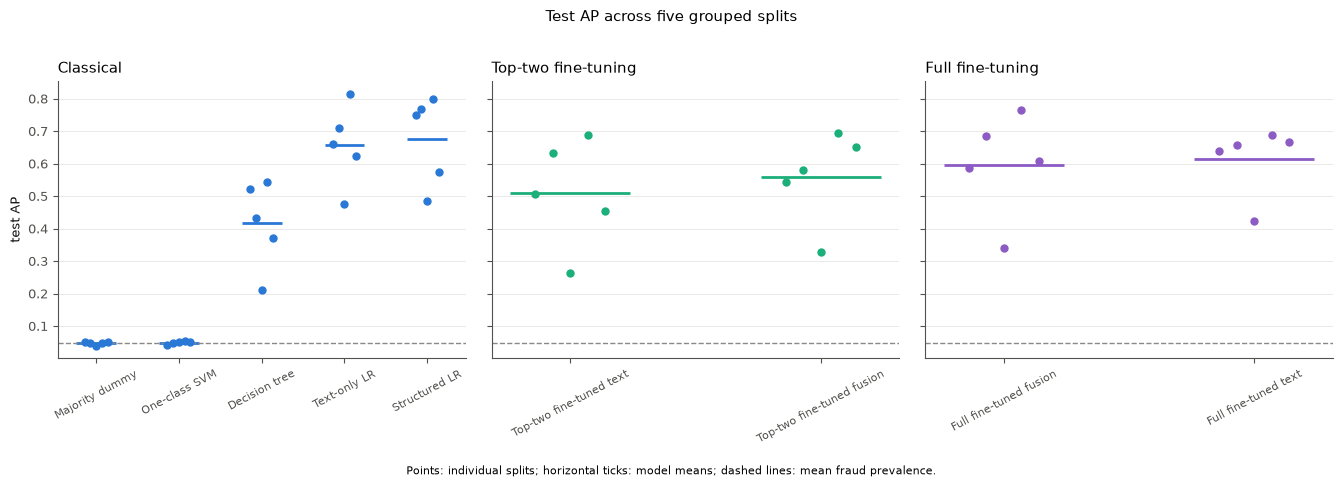

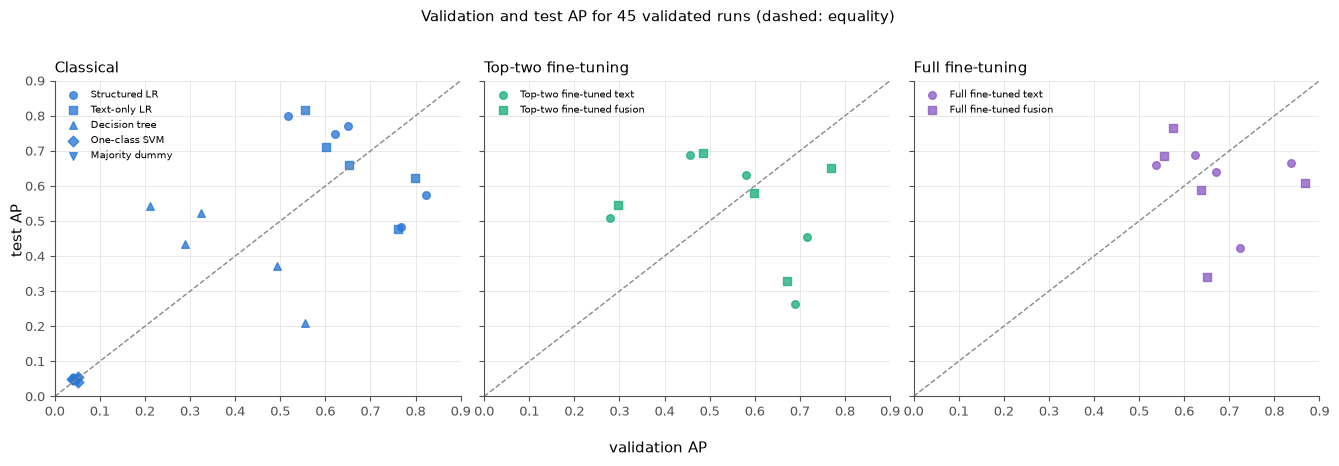

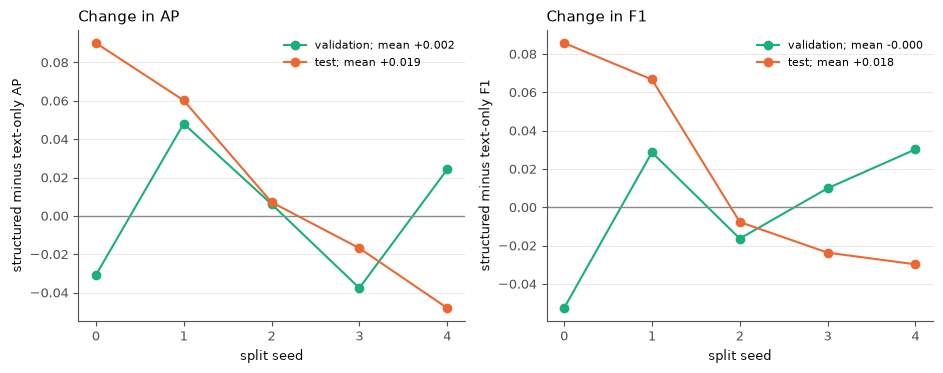

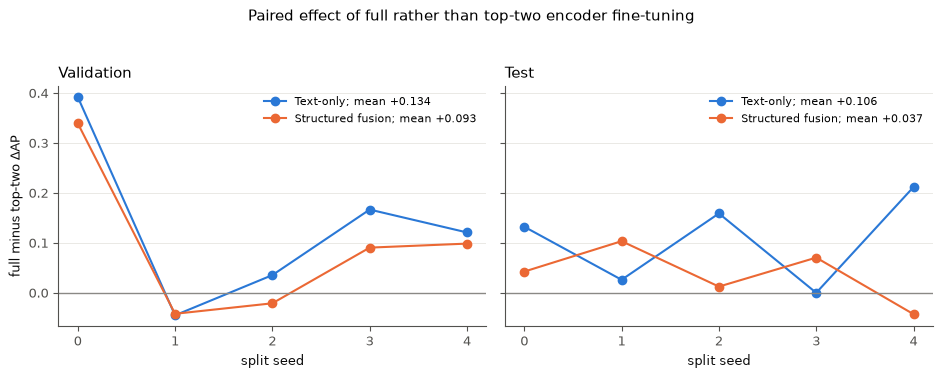

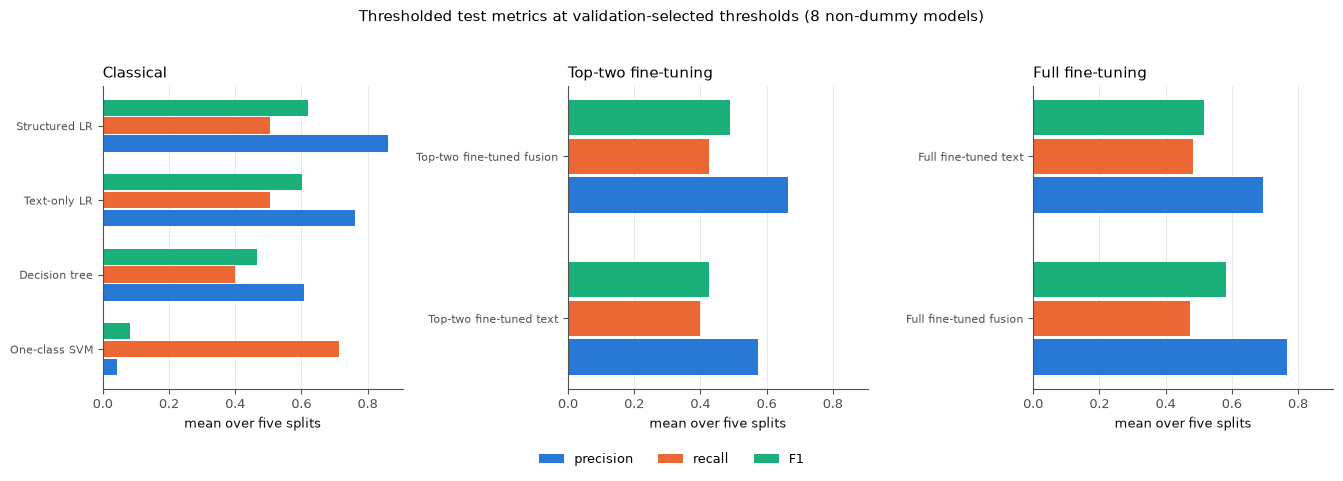

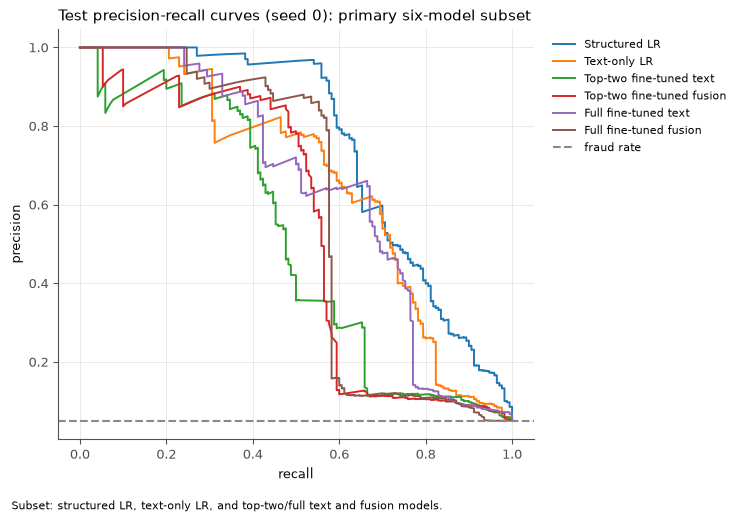

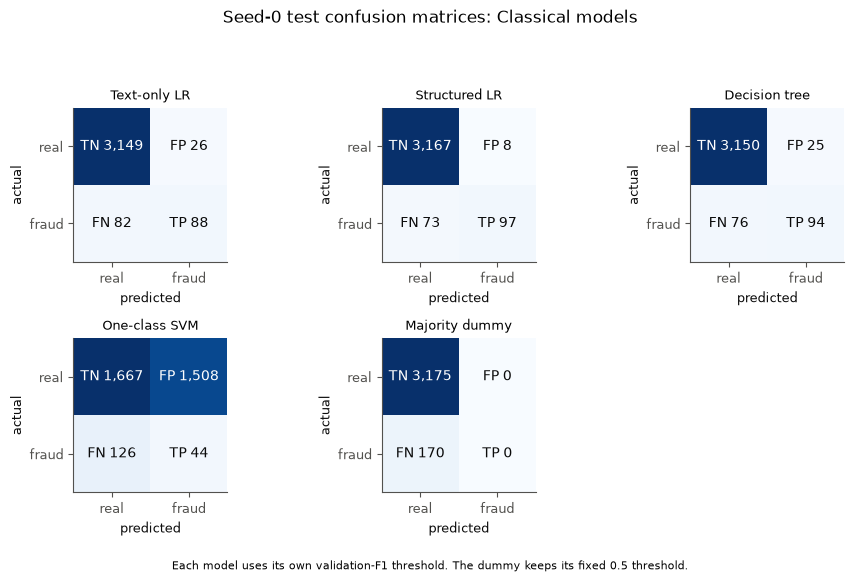

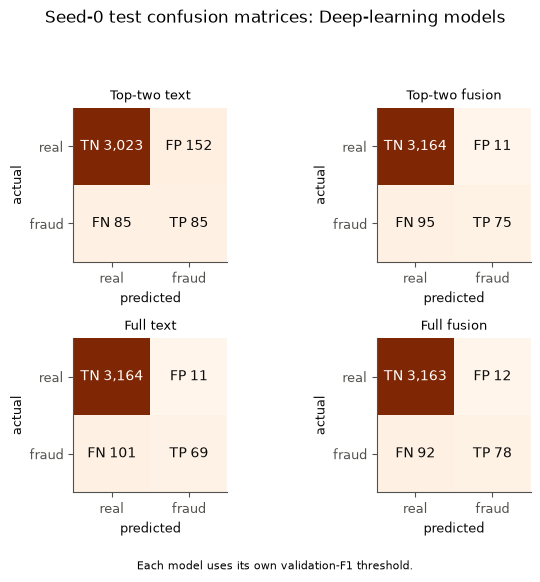

In [10]:
# Report figures and tables. Families are keyed by the stored result group.
RUN_DIRS = {STORED_GROUPS[arm]: DIRS[arm] for arm in DIRS}
FAMILY_MODELS = {
    "classical": ("logreg", "logreg_text", "tree", "ocsvm", "dummy_majority"),
    "finetuned_top2": ("distilbert_top2_text", "distilbert_top2_fused"),
    "finetuned": ("distilbert_text", "distilbert_fused"),
}
FAMILY_COLOR = {"classical": rp.BLUE, "finetuned_top2": rp.AQUA, "finetuned": rp.PURPLE}
FAMILY_TITLE = {"classical": "Classical", "finetuned_top2": "Top-two fine-tuning",
                "finetuned": "Full fine-tuning"}
NAMES = {
    "dummy_majority": "Majority dummy", "logreg_text": "Text-only LR", "logreg": "Structured LR",
    "tree": "Decision tree", "ocsvm": "One-class SVM",
    "distilbert_top2_text": "Top-two fine-tuned text", "distilbert_top2_fused": "Top-two fine-tuned fusion",
    "distilbert_text": "Full fine-tuned text", "distilbert_fused": "Full fine-tuned fusion",
}
MARKERS = ("o", "s", "^", "D", "v")
PRIMARY_PR_MODELS = ("logreg", "logreg_text", "distilbert_top2_text", "distilbert_top2_fused",
                     "distilbert_text", "distilbert_fused")
ADAPTATION_ARMS = (("Text-only", "distilbert_text", "distilbert_top2_text"),
                   ("Structured fusion", "distilbert_fused", "distilbert_top2_fused"))
FUSION_ARMS = (("Top-two fine-tuning", "distilbert_top2_fused", "distilbert_top2_text"),
               ("Full fine-tuning", "distilbert_fused", "distilbert_text"))
LATEX_END = r" \\"


def pm(series):
    """Format mean and sample standard deviation for one result column."""
    return f"${series.mean():.3f} \\pm {series.std():.3f}$"


def paired_delta(res, left, right, split, metric):
    """Return one ordered left-minus-right difference per matched split."""
    paired = res[res["model"].isin([left, right])].pivot(
        index="seed", columns="model", values=f"{split}_{metric}"
    )
    return (paired[left] - paired[right]).reindex(SEEDS)


def fig_seed_ap(res):
    """Per-seed test AP and model means in readable family facets."""
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8), sharey=True)
    prevalence = res.loc[res["model"] == "dummy_majority", "test_pr_auc"].mean()
    for ax, (family, expected) in zip(axes.flat, FAMILY_MODELS.items()):
        means = res[res["group"] == family].groupby("model")["test_pr_auc"].mean()
        order = means.loc[list(expected)].sort_values().index
        color = FAMILY_COLOR[family]
        for position, model in enumerate(order):
            rows = res[res["model"] == model].sort_values("seed")
            x = position + np.linspace(-0.14, 0.14, len(rows))
            ax.scatter(x, rows["test_pr_auc"], color=color, s=25, zorder=3)
            ax.hlines(
                rows["test_pr_auc"].mean(), position - 0.24, position + 0.24,
                color=color, linewidth=2
            )
        ax.axhline(prevalence, color=rp.GRAY, linestyle="--", linewidth=1)
        ax.set_xticks(range(len(order)), [NAMES[name] for name in order])
        ax.tick_params(axis="x", rotation=28, labelsize=8)
        ax.set_title(FAMILY_TITLE[family], loc="left")
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("test AP")
    fig.suptitle("Test AP across five grouped splits")
    fig.text(
        0.5, 0.012,
        "Points: individual splits; horizontal ticks: model means; dashed lines: mean fraud prevalence.",
        ha="center", fontsize=8
    )
    fig.tight_layout(rect=(0, 0.045, 1, 0.96))
    rp.save_figure(fig, "test_ap_by_seed.pdf")


def fig_validation_test(res):
    """Validation/test AP pairs for all 45 runs in family facets."""
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6), sharex=True, sharey=True)
    for ax, (family, models) in zip(axes.flat, FAMILY_MODELS.items()):
        ax.plot([0, 0.9], [0, 0.9], color=rp.GRAY, linestyle="--", linewidth=1)
        for model, marker in zip(models, MARKERS):
            rows = res[res["model"] == model]
            ax.scatter(
                rows["val_pr_auc"], rows["test_pr_auc"], s=30, alpha=0.78,
                color=FAMILY_COLOR[family], marker=marker, label=NAMES[model]
            )
        ax.set_xlim(0, 0.9)
        ax.set_ylim(0, 0.9)
        ax.set_title(FAMILY_TITLE[family], loc="left")
        ax.legend(loc="upper left", fontsize=7)
    fig.supxlabel("validation AP")
    fig.supylabel("test AP")
    fig.suptitle("Validation and test AP for 45 validated runs (dashed: equality)")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    rp.save_figure(fig, "validation_vs_test_ap.pdf")


def fig_feature_ablation(res):
    """Structured-minus-text LR deltas in AP and F1."""
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
    for ax, metric, label in ((axes[0], "pr_auc", "AP"), (axes[1], "f1", "F1")):
        for split, color in (("val", rp.AQUA), ("test", rp.ORANGE)):
            paired = res[res["model"].isin(["logreg", "logreg_text"])].pivot(
                index="seed", columns="model", values=f"{split}_{metric}"
            )
            delta = paired["logreg"] - paired["logreg_text"]
            label_name = "validation" if split == "val" else "test"
            ax.plot(delta.index, delta.values, marker="o", color=color,
                    label=f"{label_name}; mean {delta.mean():+.3f}")
        ax.axhline(0, color=rp.GRAY, linewidth=1)
        ax.set_xticks(range(5))
        ax.set_xlabel("split seed")
        ax.set_ylabel(f"structured minus text-only {label}")
        ax.set_title(f"Change in {label}", loc="left")
        ax.grid(axis="x", visible=False)
        ax.legend(fontsize=8)
    fig.tight_layout()
    rp.save_figure(fig, "feature_ablation.pdf")


def fig_adaptation_ablation(res):
    """Paired full-minus-top-two AP deltas separately for validation and test."""
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=True)
    for ax, split in zip(axes, ("val", "test")):
        for (label, full, top2), color in zip(ADAPTATION_ARMS, (rp.BLUE, rp.ORANGE)):
            delta = paired_delta(res, full, top2, split, "pr_auc")
            ax.plot(
                delta.index, delta.values, marker="o", color=color,
                label=f"{label}; mean {delta.mean():+.3f}"
            )
        ax.axhline(0, color=rp.GRAY, linewidth=1)
        ax.set_xticks(SEEDS)
        ax.set_xlabel("split seed")
        ax.set_title("Validation" if split == "val" else "Test", loc="left")
        ax.grid(axis="x", visible=False)
        ax.legend(fontsize=8)
    axes[0].set_ylabel("full minus top-two $\\Delta$AP")
    fig.suptitle("Paired effect of full rather than top-two encoder fine-tuning")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    rp.save_figure(fig, "adaptation_ablation.pdf")


def fig_metric_profile(res):
    """Mean thresholded precision, recall, and F1 by non-dummy model and family."""
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8), sharex=True)
    means = res.groupby("model")[["test_pr_auc", "test_precision", "test_recall", "test_f1"]].mean()
    for ax, (family, expected) in zip(axes.flat, FAMILY_MODELS.items()):
        models = [name for name in expected if name != "dummy_majority"]
        order = means.loc[models, "test_pr_auc"].sort_values().index
        y = np.arange(len(order))
        for offset, metric, color, label in (
            (-0.24, "test_precision", rp.BLUE, "precision"),
            (0.0, "test_recall", rp.ORANGE, "recall"),
            (0.24, "test_f1", rp.AQUA, "F1"),
        ):
            ax.barh(y + offset, means.loc[order, metric], height=0.22, color=color, label=label)
        ax.set_yticks(y, [NAMES[name] for name in order], fontsize=8)
        ax.set_title(FAMILY_TITLE[family], loc="left")
        ax.grid(axis="y", visible=False)
    for ax in axes:
        ax.set_xlabel("mean over five splits")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.006), ncol=3)
    fig.suptitle("Thresholded test metrics at validation-selected thresholds (8 non-dummy models)")
    fig.tight_layout(rect=(0, 0.075, 1, 0.95))
    rp.save_figure(fig, "metric_profile.pdf")


def fig_pr_curves(res):
    """Seed-0 precision-recall curves for the stated primary model subset."""
    fig, ax = plt.subplots(figsize=(7.5, 5.2))
    y_test = None
    seed0 = res[res["seed"] == 0].set_index("model")
    for name in PRIMARY_PR_MODELS:
        scores = rh.load_scores(RUN_DIRS[seed0.loc[name, "group"]], name, 0)
        if y_test is None:
            y_test = scores["y_test"]
        assert np.array_equal(y_test, scores["y_test"])
        precision, recall, _ = precision_recall_curve(y_test, scores["score_test"])
        ax.plot(recall, precision, label=NAMES[name], linewidth=1.4)
    ax.axhline(y_test.mean(), color=rp.GRAY, linestyle="--", label="fraud rate")
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.set_title("Test precision-recall curves (seed 0): primary six-model subset", loc="left")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
    fig.text(
        0.02, 0.012,
        "Subset: structured LR, text-only LR, and top-two/full text and fusion models.",
        fontsize=8
    )
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    rp.save_figure(fig, "pr_curves_seed0.pdf")


def fig_confusion_matrices(res):
    """Plot all seed-0 confusion matrices by technique family."""
    families = (
        (
            "Classical models", "confusion_classical.pdf", "Blues", (2, 3),
            (
                ("logreg_text", "Text-only LR"), ("logreg", "Structured LR"),
                ("tree", "Decision tree"), ("ocsvm", "One-class SVM"),
                ("dummy_majority", "Majority dummy"),
            ),
        ),
        (
            "Deep-learning models", "confusion_deep.pdf", "Oranges", (2, 2),
            (
                ("distilbert_top2_text", "Top-two text"),
                ("distilbert_top2_fused", "Top-two fusion"),
                ("distilbert_text", "Full text"), ("distilbert_fused", "Full fusion"),
            ),
        ),
    )
    seed0 = res[res["seed"] == 0].set_index("model")
    states = (("TN", "FP"), ("FN", "TP"))
    for title, filename, color_map, shape, models in families:
        fig, axes = plt.subplots(*shape, figsize=(3.15 * shape[1], 5.8), squeeze=False)
        for ax, (name, label) in zip(axes.flat, models):
            scores = rh.load_scores(RUN_DIRS[seed0.loc[name, "group"]], name, 0)
            threshold = float(seed0.loc[name, "thr"])
            metrics = ev.evaluate(scores["y_test"], scores["score_test"], threshold)
            matrix = np.array([
                [metrics["tn"], metrics["fp"]], [metrics["fn"], metrics["tp"]],
            ])
            vmax = max(1, int(matrix[0].max()))
            ax.imshow(matrix, cmap=color_map, vmin=0, vmax=vmax)
            ax.set_xticks([0, 1], ["real", "fraud"])
            ax.set_yticks([0, 1], ["real", "fraud"])
            ax.set_xlabel("predicted")
            ax.set_ylabel("actual")
            ax.set_title(label, fontsize=9)
            ax.grid(visible=False)
            for actual in (0, 1):
                for predicted in (0, 1):
                    count = int(matrix[actual, predicted])
                    ax.text(
                        predicted, actual, f"{states[actual][predicted]} {count:,}",
                        ha="center", va="center", fontsize=10,
                        color="white" if count > 0.62 * vmax else rp.INK,
                    )
        for ax in axes.flat[len(models):]:
            ax.set_visible(False)
        fig.suptitle(f"Seed-0 test confusion matrices: {title}", fontsize=12)
        threshold_note = "Each model uses its own validation-F1 threshold."
        if any(model == "dummy_majority" for model, _ in models):
            threshold_note += " The dummy keeps its fixed 0.5 threshold."
        fig.text(0.5, 0.015, threshold_note, ha="center", fontsize=8)
        fig.tight_layout(rect=(0, 0.05, 1, 0.92))
        rp.save_figure(fig, filename)


def write_result_tables(res):
    """Write family-headline and paired-ablation LaTeX tables."""
    families = (
        ("tab_classical_results.tex", ("classical",)),
        ("tab_deep_results.tex", ("finetuned_top2", "finetuned")),
    )
    for filename, groups in families:
        models = [model for group in groups for model in FAMILY_MODELS[group]]
        subset = res[res["model"].isin(models)]
        order = subset.groupby("model")["test_pr_auc"].mean().sort_values(ascending=False).index
        lines = []
        for name in order:
            rows = subset[subset["model"] == name]
            cells = [pm(rows[f"test_{metric}"]) for metric in ("pr_auc", "f1", "precision", "recall")]
            lines.append(f"{rp.tex(NAMES[name])} & " + " & ".join(cells)
                         + f" & {rows['seconds'].mean():.1f}" + LATEX_END)
        with open(os.path.join(rp.INCLUDES, filename), "w") as f:
            f.write("\n".join(lines) + "\n")

    lines = []
    for metric, label in (("pr_auc", "AP"), ("f1", "F1")):
        for split in ("val", "test"):
            paired = res[res["model"].isin(["logreg", "logreg_text"])].pivot(
                index="seed", columns="model", values=f"{split}_{metric}"
            )
            delta = paired["logreg"] - paired["logreg_text"]
            split_label = "validation" if split == "val" else "test"
            lines.append(f"{split_label} {label} & " + " & ".join(f"{x:+.3f}" for x in delta)
                         + f" & {delta.mean():+.3f} & {int((delta > 0).sum())}/5" + LATEX_END)
    with open(os.path.join(rp.INCLUDES, "tab_paired.tex"), "w") as f:
        f.write("\n".join(lines) + "\n")

    for filename, arms in (("tab_adaptation.tex", ADAPTATION_ARMS), ("tab_fusion.tex", FUSION_ARMS)):
        lines = []
        for label, left, right in arms:
            val_ap = paired_delta(res, left, right, "val", "pr_auc")
            test_ap = paired_delta(res, left, right, "test", "pr_auc")
            test_f1 = paired_delta(res, left, right, "test", "f1")
            lines.append(
                f"{rp.tex(label)} & {val_ap.mean():+.3f} & {test_ap.mean():+.3f} & "
                f"{test_f1.mean():+.3f} & {int((test_ap > 0).sum())}/5 & "
                f"{int((test_f1 > 0).sum())}/5" + LATEX_END
            )
        with open(os.path.join(rp.INCLUDES, filename), "w") as f:
            f.write("\n".join(lines) + "\n")
    print("wrote result tables", flush=True)


for make in (fig_seed_ap, fig_validation_test, fig_feature_ablation, fig_adaptation_ablation,
             fig_metric_profile, fig_pr_curves, fig_confusion_matrices, write_result_tables):
    make(res)
plt.show()